# Dashboard checks in a browser

**Data source:** the dashboard pages in `../dashboard/` (`index.html`, `detail.html`), built from `build_dashboard.ipynb`.
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Opens both screens straight from the folder (a `file://` address, with no server and no internet, exactly as the professor will) in a headless Chromium browser, and checks what they show at first load: no errors, no file requested from the internet, every chart drawn as SVG, the KPIs filled in, and the page structure (language, skip links, headings). It then uses every interaction of Part 5 as a user would and reads the result back from the page (task 6.5), and takes screenshots at 1280 × 800 px. Then it uses both screens with the keyboard only (task 6.6), checks the text alternatives, data tables, contrast, 200 % zoom, tablet widths and HTML (task 6.7), and reviews every item of the WCAG checklist.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: first load, interactions and keyboard](#4.-Analysis:-checks-at-first-load)
5. [Accessible visualisation: screenshots](#5.-Accessible-visualisation:-screenshots)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd

# Playwright drives a real browser. If it is missing: pip install playwright, then: playwright install chromium
from playwright.async_api import async_playwright

DASHBOARD_DIR = Path('../dashboard').resolve()
OUTPUT_DIR = Path('browser_checks_output')
OUTPUT_DIR.mkdir(exist_ok=True)
SCREEN_SIZE = {'width': 1280, 'height': 800}        # minimum screen of Part 4

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| playwright', version('playwright'))

Python 3.13.18 | pandas 3.0.5 | playwright 1.63.0


## 1. Data loading

The "data" of this notebook are the two pages. Each one is opened with a `file://` address.

In [2]:
# ── The pages and the charts each one must draw ──────────────────────────────
PAGES = {'index.html': ['c1', 'c2', 'c3'], 'detail.html': ['c4', 'c6', 'c7', 'c8', 'c5']}
page_files = pd.DataFrame([(name, (DASHBOARD_DIR / name).exists(), (DASHBOARD_DIR / name).as_uri()) for name in PAGES],
                          columns=['page', 'exists', 'address'])
page_files

,page,exists,address
0,index.html,True,file:///home/claude/cn/Delivery%201/Part%206%2...
1,detail.html,True,file:///home/claude/cn/Delivery%201/Part%206%2...


## 2. Initial exploration

The files the pages load, with their size: the data, the chart specs and the local copies of the libraries.

In [3]:
# ── Files of the dashboard folder ─────────────────────────────────────────────
pd.DataFrame([(str(path.relative_to(DASHBOARD_DIR)), round(path.stat().st_size / 1024, 1))
              for path in sorted(DASHBOARD_DIR.rglob('*')) if path.is_file()], columns=['file', 'KB'])

,file,KB
0,accessibility.html,7.1
1,dashboard.css,9.9
2,dashboard.js,41.6
3,data.js,255.1
4,detail.html,10.2
5,index.html,7.2
6,lib/LICENSE-vega-embed.txt,1.5
7,lib/LICENSE-vega-lite.txt,1.5
8,lib/LICENSE-vega.txt,1.5
9,lib/vega-6.2.0.min.js,500.4


## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: checks at first load

In [4]:
# ── Open each page and collect what it shows ─────────────────────────────────
# Top-level await works in Jupyter; the async API is used because the notebook already runs an event loop.

async def check_page(browser, page_name, charts):
    context = await browser.new_context(viewport=SCREEN_SIZE, device_scale_factor=1)
    page = await context.new_page()
    problems, requests = [], []
    page.on('console', lambda message: problems.append(f'{message.type}: {message.text}')
            if message.type in ('error', 'warning') else None)
    page.on('pageerror', lambda error: problems.append(f'page error: {error}'))
    page.on('request', lambda request: requests.append(request.url))
    await page.goto((DASHBOARD_DIR / page_name).as_uri())
    await page.wait_for_function('names => names.every(n => document.querySelector("#" + n + " svg"))', arg=charts, timeout=20000)
    found = await page.evaluate("""charts => ({
        lang: document.documentElement.lang,
        skip_links: [...document.querySelectorAll('.skip-link')].map(a => a.textContent),
        headings: [...document.querySelectorAll('h1, h2, h3')].map(h => h.tagName + ' ' + h.textContent),
        kpis: [...document.querySelectorAll('.kpi')].map(k => [k.querySelector('dt').textContent,
               k.querySelector('.kpi-value').textContent, k.querySelector('.kpi-context').textContent]),
        showing: document.getElementById('active-filters-text').textContent,
        charts: charts.map(c => {
            const svg = document.querySelector('#' + c + ' svg');
            return {chart: c, svg: !!svg, canvas: !!document.querySelector('#' + c + ' canvas'),
                    marks_with_label: svg ? svg.querySelectorAll('.role-mark [aria-label]').length : 0,
                    heading_as_spec: document.getElementById(c + '-title').textContent === DASHBOARD_SPECS[c].title.text,
                    caption_as_spec: document.getElementById(c + '-short').textContent === DASHBOARD_SPECS[c].description};
        })
    })""", charts)
    await page.screenshot(path=OUTPUT_DIR / page_name.replace('.html', '_1280x800.png'))
    await page.screenshot(path=OUTPUT_DIR / page_name.replace('.html', '_full_page.png'), full_page=True)
    await context.close()
    found.update(page=page_name, problems=problems,
                 internet_requests=[url for url in requests if not url.startswith('file://')],
                 files_loaded=[url.rsplit('/', 1)[-1] for url in requests])
    return found


async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    first_load = [await check_page(browser, name, charts) for name, charts in PAGES.items()]
    await browser.close()
print('Pages checked:', [result['page'] for result in first_load])

Pages checked: ['index.html', 'detail.html']


In [5]:
# ── Summary of the checks at first load ──────────────────────────────────────
summary = pd.DataFrame([{
    'page': r['page'],
    'lang="en"': r['lang'] == 'en',
    'errors or warnings': len(r['problems']),
    'files from the internet': len(r['internet_requests']),
    'charts drawn as SVG': sum(c['svg'] and not c['canvas'] for c in r['charts']),
    'charts expected': len(r['charts']),
    'KPIs filled in': sum(value not in ('', '–') for _, value, _ in r['kpis']),
    'skip links': len(r['skip_links']),
    'headings = chart titles': all(c['heading_as_spec'] and c['caption_as_spec'] for c in r['charts']),
} for r in first_load])
print('Everything as expected:', bool((summary['errors or warnings'] == 0).all() and (summary['files from the internet'] == 0).all()
                                      and (summary['charts drawn as SVG'] == summary['charts expected']).all()
                                      and (summary['KPIs filled in'] == 4).all() and summary['headings = chart titles'].all()))
summary

Everything as expected: True


,page,"lang=""en""",errors or warnings,files from the internet,charts drawn as SVG,charts expected,KPIs filled in,skip links,headings = chart titles
0,index.html,True,0,0,3,3,4,2,True
1,detail.html,True,0,0,5,5,4,2,True


In [6]:
# ── What each page shows: KPIs, charts and heading structure ─────────────────
for r in first_load:
    print(f"\n{r['page']} | Showing: {r['showing']} | files loaded: {', '.join(r['files_loaded'][1:])}")
    for label, value, context in r['kpis']:
        print(f'  KPI  {label}: {value} ({context})')
    for c in r['charts']:
        print(f"  {c['chart']}: SVG {c['svg']}, marks with an aria-label: {c['marks_with_label']}")
    print('  Headings:', ' / '.join(r['headings']))


index.html | Showing: Both hotels · All years (July 2015 to August 2017) | files loaded: dashboard.css, data.js, specs.js, vega-6.2.0.min.js, vega-lite-6.4.1.min.js, vega-embed-7.1.0.min.js, dashboard.js
  KPI  Stays: 75,007 (bookings not cancelled, of 119,201)
  KPI  Guests: 145,980 (people in those stays)
  KPI  Bookings cancelled: 37.1 % (of 119,201 bookings; duplicates included (see note))
  KPI  Median price per night: €94.5 (median of stays with a price; euros assumed)
  c1: SVG True, marks with an aria-label: 52
  c2: SVG True, marks with an aria-label: 52
  c3: SVG True, marks with an aria-label: 52
  Headings: H1 Hotel guests in Lisbon and the Algarve / H2 Key figures for the selected filters / H2 Charts / H3 In which months do the city and the resort receive most guests? / H3 In which months are most bookings cancelled? / H3 How does the price per night change through the year? / H2 Filters / H3 Selected month

detail.html | Showing: Both hotels · All years (July 2015 to Aug

**Finding:** both pages open from the folder with no server and no internet (every file comes from `file://`), with no error or warning in the console, every chart drawn as SVG, the four KPIs filled in for the default filters, `lang="en"`, two skip links and one heading per chart equal to the chart's title.

### 4.2 Interactions (task 6.5)

Each interaction of Part 5 is done in the browser as a user would (clicking, choosing, pointing), and the result is read back from the page: the KPIs, the marks of the charts, the live regions that a screen reader announces, and the link to the other screen. The expected numbers come from the aggregated tables of `build_dashboard.ipynb` (`data/processed/`).

In [7]:
# ── Expected values, from the tables of task 6.1 ─────────────────────────────
filter_kpis = pd.read_csv('../../data/processed/dashboard_filter_kpis.csv', keep_default_na=False)
country_medians = pd.read_csv('../../data/processed/dashboard_country_medians.csv', keep_default_na=False)
month_hotel_table = pd.read_csv('../../data/processed/dashboard_month_hotel.csv', keep_default_na=False)

def expected_kpi(hotel, year, column):
    row = filter_kpis[(filter_kpis['hotel_filter'] == hotel) & (filter_kpis['year_filter'] == str(year))].iloc[0]
    return row[column]

def guests_order(hotel, year):
    rows = country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))
                           & (country_medians['country_group'] != 'Other')]
    return rows.sort_values('guests', ascending=False)['country_group'].tolist() + ['Other']

print('Stays, City Hotel, 2016:', f"{expected_kpi('City Hotel', 2016, 'stays'):,}",
      '| country order (both hotels, all years):', guests_order('Both', 'All'))

Stays, City Hotel, 2016: 22,662 | country order (both hotels, all years): ['Portugal', 'United Kingdom', 'France', 'Spain', 'Germany', 'Ireland', 'Italy', 'Belgium', 'Netherlands', 'United States', 'Other']


In [8]:
# ── Helpers that read the page ───────────────────────────────────────────────
READ_PAGE = """() => ({
    showing: document.getElementById('active-filters-text').textContent,
    announcer: document.getElementById('announcer').textContent,
    kpis: Object.fromEntries([...document.querySelectorAll('.kpi')].map(k => [k.querySelector('dt').textContent, k.querySelector('.kpi-value').textContent])),
    link: document.getElementById('link-other-screen').getAttribute('href'),
    month: document.getElementById('month-details') ? document.getElementById('month-details').textContent.replace(/\\s+/g, ' ').trim() : null,
    country: document.getElementById('country-details') ? document.getElementById('country-details').textContent.replace(/\\s+/g, ' ').trim() : null,
    points: Object.fromEntries(['c1','c2','c3','c4','c6','c7','c8','c5'].filter(c => document.getElementById(c)).map(
        c => [c, document.querySelectorAll('#' + c + ' .role-mark [aria-label]').length])),
    visible_rules: Object.fromEntries(['c1','c2','c3'].filter(c => document.getElementById(c)).map(
        c => [c, [...document.querySelectorAll('#' + c + ' .mark-rule.role-mark line')].filter(l => l.getAttribute('opacity') !== '0').length])),
    orange_bars: Object.fromEntries(['c4','c7','c8'].filter(c => document.getElementById(c)).map(
        c => [c, document.querySelectorAll('#' + c + ' .mark-rect path[data-selected="true"]').length])),
    c4_order: (() => { const g = document.querySelector('#c4 .role-axis-label'); return g ? [...g.querySelectorAll('text')].map(t => t.textContent) : []; })(),
    previous_disabled: document.getElementById('previous-country') ? document.getElementById('previous-country').disabled : null,
    next_disabled: document.getElementById('next-country') ? document.getElementById('next-country').disabled : null,
    tooltip: document.getElementById('vg-tooltip-element') ? document.getElementById('vg-tooltip-element').textContent : '',
    tooltip_visible: !!document.querySelector('#vg-tooltip-element.visible'),
})"""

def count(value):
    return f'{value:,}'

HOTEL_LABELS_TEXT = {'Both': 'Both hotels', 'City Hotel': 'City Hotel (Lisbon)', 'Resort Hotel': 'Resort Hotel (Algarve)'}

async def open_page(browser, address):
    context = await browser.new_context(viewport=SCREEN_SIZE)
    page = await context.new_page()
    problems = []
    page.on('console', lambda message: problems.append(message.text) if message.type in ('error', 'warning') else None)
    page.on('pageerror', lambda error: problems.append(str(error)))
    await page.goto(address)
    await page.wait_for_selector('body[data-dashboard-ready="true"]', timeout=20000)
    return context, page, problems

async def settle(page):
    await page.wait_for_timeout(400)          # let Vega redraw and the announcer update

async def mark_centre(page, chart, label_start):
    box = await page.locator(f'#{chart} .role-mark [aria-label^="{label_start}"]').first.bounding_box()
    return box['x'] + box['width'] / 2, box['y'] + box['height'] / 2

print('Helpers ready')

Helpers ready


In [9]:
# ── Main screen: I1 hotel filter, I2 year filter, I3 link, I5 linked month, I6 tooltip, I4 reset ─
checks = []
def check(interaction, what, passed, seen):
    checks.append({'interaction': interaction, 'check': what, 'passes': bool(passed), 'seen in the page': str(seen)[:160]})

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'index.html').as_uri())

    await page.check('#hotel-city'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I1 Hotel filter', 'KPI stays = City Hotel, all years', seen['kpis']['Stays'] == count(expected_kpi('City Hotel', 'All', 'stays')), seen['kpis']['Stays'])
    check('I1 Hotel filter', 'C1-C3 draw only the 26 City Hotel months', seen['points'] == {'c1': 26, 'c2': 26, 'c3': 26}, seen['points'])
    check('I1 Hotel filter', '"Showing" (a live region) announces City Hotel', seen['showing'].startswith('City Hotel'), seen['showing'])

    await page.select_option('#year', '2016'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I2 Year filter', 'KPI guests = City Hotel, 2016', seen['kpis']['Guests'] == count(expected_kpi('City Hotel', 2016, 'guests')), seen['kpis']['Guests'])
    check('I2 Year filter', 'C1-C3 draw the 12 months of 2016', seen['points'] == {'c1': 12, 'c2': 12, 'c3': 12}, seen['points'])
    check('I2 Year filter', '"Showing" announces 2016', seen['showing'] == 'City Hotel (Lisbon) · 2016', seen['showing'])
    check('I3 Filters kept between screens', 'the link to the detail screen carries the filters', seen['link'] == 'detail.html?hotel=City+Hotel&year=2016', seen['link'])

    x, y = await mark_centre(page, 'c1', 'City Hotel, August 2016')
    await page.mouse.move(x, y); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    august = month_hotel_table[(month_hotel_table['arrival_month'] == '2016-08-01') & (month_hotel_table['hotel'] == 'City Hotel')].iloc[0]
    check('I5 Linked month', 'pointing at August 2016 in C1 writes its exact values in the box (a live region)',
          seen['month'].startswith('August 2016') and f"City Hotel: {count(august['guests'])} guests, {august['cancel_rate']:.1f}" in seen['month']
          and f"€{august['median_price']:.1f}" in seen['month'], seen['month'])
    check('I5 Linked month', 'a dashed rule marks August 2016 in C1, C2 and C3', seen['visible_rules'] == {'c1': 1, 'c2': 1, 'c3': 1}, seen['visible_rules'])
    check('I6 Tooltips', 'the tooltip shows the month, the hotel and the guests with separators',
          seen['tooltip_visible'] and 'August 2016' in seen['tooltip'] and 'City Hotel' in seen['tooltip']
          and count(august['guests']) in seen['tooltip'] and 'undefined' not in seen['tooltip'], seen['tooltip'])
    await page.screenshot(path=OUTPUT_DIR / 'index_month_linked_1280x800.png')
    await page.mouse.move(5, 5); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I5 Linked month', 'the month stays linked when the pointer leaves', seen['visible_rules'] == {'c1': 1, 'c2': 1, 'c3': 1} and seen['month'].startswith('August 2016'), seen['visible_rules'])

    await page.click('#reset-filters'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I4 Reset filters', 'KPIs back to both hotels, all years', seen['kpis']['Stays'] == count(expected_kpi('Both', 'All', 'stays')), seen['kpis']['Stays'])
    check('I4 Reset filters', 'controls back to Both and All', await page.is_checked('#hotel-both') and await page.input_value('#year') == 'All', 'radio and select')
    check('I4 Reset filters', 'the reset is announced', seen['announcer'].startswith('Filters reset'), seen['announcer'])
    check('I4 Reset filters', 'C1-C3 draw all 52 points again', seen['points'] == {'c1': 52, 'c2': 52, 'c3': 52}, seen['points'])
    main_problems = list(problems)
    await context.close()

    # I3: open the detail screen as the link does, with the filters in the address
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri() + '?hotel=City+Hotel&year=2016')
    seen = await page.evaluate(READ_PAGE)
    check('I3 Filters kept between screens', 'the detail screen opens with City Hotel and 2016 chosen',
          await page.is_checked('#hotel-city') and await page.input_value('#year') == '2016', seen['showing'])
    check('I3 Filters kept between screens', 'its KPI "countries of origin" is the City Hotel 2016 value',
          seen['kpis']['Countries of origin'] == count(expected_kpi('City Hotel', 2016, 'countries_of_origin')), seen['kpis']['Countries of origin'])
    check('I3 Filters kept between screens', 'C4 has one panel (11 bars)', seen['points']['c4'] == 11, seen['points'])
    main_problems += list(problems)
    await context.close()
    await browser.close()
print(f'Main screen and link: {len(checks)} checks, all pass: {all(c["passes"] for c in checks)} | console problems: {main_problems}')

Main screen and link: 18 checks, all pass: True | console problems: []


In [10]:
# ── Detail screen: I7 select a country, I9 sort toggle, I8 show more, I1 on this screen ─
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri())
    order = guests_order('Both', 'All')

    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'Portugal selected at first load; Previous disabled at the first bar',
          seen['country'].startswith('Portugal') and seen['previous_disabled'] and not seen['next_disabled'], seen['country'])

    x, y = await mark_centre(page, 'c4', 'France, City Hotel')
    await page.mouse.click(x, y); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    france = country_medians.query("hotel_filter == 'Both' and year_filter == 'All' and country_group == 'France'").iloc[0]
    check('I7 Select a country', 'a click on the France bar writes France and its guests in the box (a live region)',
          seen['country'].startswith('France') and count(france['guests']) in seen['country'], seen['country'])
    check('I7 Select a country', 'France is orange and striped in C4 (2 panels), C7 and C8', seen['orange_bars'] == {'c4': 2, 'c7': 1, 'c8': 1}, seen['orange_bars'])
    check('I7 Select a country', 'the KPIs follow the selection', seen['kpis'].get('Guests from France') == count(france['guests']), seen['kpis'])

    await page.click('#next-country'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    expected_next = order[order.index('France') + 1]
    check('I7 Select a country', f'Next goes to the following bar ({expected_next})', seen['country'].startswith(expected_next), seen['country'])
    await page.click('#previous-country'); await page.click('#previous-country'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    expected_previous = order[order.index('France') - 1]
    check('I7 Select a country', f'Previous twice goes back to {expected_previous}', seen['country'].startswith(expected_previous), seen['country'])
    name_fits = await page.evaluate("""name => {
        const svg = document.querySelector('#c6 svg');
        const label = [...svg.querySelectorAll('text')].find(text => text.textContent === name);
        return !!label && label.getBoundingClientRect().right <= svg.getBoundingClientRect().right; }""", expected_previous)
    check('I7 Select a country', f'the name {expected_previous} fits at the end of its line in C6', name_fits, name_fits)

    await page.check('#sort-alphabetical'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I9 Sort toggle', 'C4 becomes alphabetical with Other last', seen['c4_order'] == sorted(order[:-1]) + ['Other'], seen['c4_order'])
    check('I9 Sort toggle', 'the new order is announced', 'alphabetically' in seen['announcer'], seen['announcer'])
    check('I9 Sort toggle', 'the selected country stays selected', seen['orange_bars']['c4'] == 2, seen['orange_bars'])
    await page.check('#sort-guests'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I9 Sort toggle', 'back to the order by guests', seen['c4_order'] == order, seen['c4_order'])

    hidden_before = await page.is_hidden('#more-charts')
    await page.click('#show-more'); await settle(page)
    expanded = await page.get_attribute('#show-more', 'aria-expanded')
    c7_box = await page.locator('#c7 svg.marks').bounding_box()
    check('I8 Show more', 'the hidden charts appear and aria-expanded becomes true',
          hidden_before and expanded == 'true' and c7_box is not None and c7_box['height'] > 0, f'aria-expanded={expanded}, C7 box {c7_box}')
    await page.screenshot(path=OUTPUT_DIR / 'detail_show_more_full_page.png', full_page=True)
    await page.click('#show-more'); await settle(page)
    check('I8 Show more', 'a second press hides them again', await page.is_hidden('#more-charts'), await page.get_attribute('#show-more', 'aria-expanded'))

    await page.check('#hotel-resort'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I1 Hotel filter', 'on the detail screen: C4 shows one panel and the KPIs change',
          seen['points']['c4'] == 11 and seen['kpis']['Countries of origin'] == count(expected_kpi('Resort Hotel', 'All', 'countries_of_origin')),
          seen['kpis']['Countries of origin'])
    detail_problems = list(problems)
    await context.close()
    await browser.close()

interaction_checks = pd.DataFrame(checks)
print(f'{len(interaction_checks)} checks, all pass: {interaction_checks["passes"].all()} | console problems on the detail screen: {detail_problems}')
interaction_checks

32 checks, all pass: True | console problems on the detail screen: []


,interaction,check,passes,seen in the page
0,I1 Hotel filter,"KPI stays = City Hotel, all years",True,"46,082"
1,I1 Hotel filter,C1-C3 draw only the 26 City Hotel months,True,"{'c1': 26, 'c2': 26, 'c3': 26}"
2,I1 Hotel filter,"""Showing"" (a live region) announces City Hotel",True,City Hotel (Lisbon) · All years (July 2015 to ...
3,I2 Year filter,"KPI guests = City Hotel, 2016",True,"44,421"
4,I2 Year filter,C1-C3 draw the 12 months of 2016,True,"{'c1': 12, 'c2': 12, 'c3': 12}"
5,I2 Year filter,"""Showing"" announces 2016",True,City Hotel (Lisbon) · 2016
6,I3 Filters kept between screens,the link to the detail screen carries the filters,True,detail.html?hotel=City+Hotel&year=2016
7,I5 Linked month,pointing at August 2016 in C1 writes its exact...,True,"August 2016City Hotel: 4,836 guests, 37.0 % of..."
8,I5 Linked month,"a dashed rule marks August 2016 in C1, C2 and C3",True,"{'c1': 1, 'c2': 1, 'c3': 1}"
9,I6 Tooltips,"the tooltip shows the month, the hotel and the...",True,MonthAugust 2016HotelCity HotelGuests who stay...


**Finding (task 6.5):** every planned interaction works in the browser and changes both what Natalia sees and what a screen reader announces. The hotel and year filters change the KPIs, the charts and the "Showing" line, and the link to the other screen carries them; the reset button brings everything back and says so; pointing at a month links it in the three charts and writes its exact values; tooltips show the values; a click on a bar, or Previous and Next, selects a country in every chart, the KPIs and the "Selected country" box; the sort toggle reorders the bars and is announced; "Show more" opens and closes the extra charts with `aria-expanded`. The arrow keys on the data points come in task 6.6.

### 4.3 Keyboard and focus (task 6.6)

The same pages are used with the keyboard only, as the wcag-accessibility skill asks: Tab through every control and chart, the arrow keys inside each chart, `Alt` + up/down arrow between series, Home/End, Enter and Escape. After each key the check reads which element has the focus, what the chart's live region announces, whether the SVG focus overlay draws a ring, and what the visible boxes say.

In [11]:
# ── Helpers for the keyboard checks ───────────────────────────────────────────
READ_FOCUS = """() => {
    const e = document.activeElement;
    const chart = e.closest('.chart-container');
    const style = getComputedStyle(e);
    const box = document.getElementById('keyboard-value');
    return {
        id: e.id, tag: e.tagName.toLowerCase(), label: e.getAttribute('aria-label') || (e.textContent || '').trim().slice(0, 60),
        chart: chart ? chart.id : null,
        announced: chart ? chart.querySelector('.chart-announcer').textContent : '',
        ring_shapes: chart ? chart.querySelector('.focus-overlay').childElementCount : 0,
        rings_elsewhere: [...document.querySelectorAll('.focus-overlay')].filter(o => !chart || o.parentElement !== chart).reduce((n, o) => n + o.childElementCount, 0),
        outline: style.outlineStyle + ' ' + style.outlineWidth + ' ' + style.outlineColor,
        value_box: box && !box.hidden ? box.textContent : '',
        dimmed: chart ? [...chart.querySelectorAll('[tabindex]')].filter(m => m.style.opacity === '0.4').length : 0,
    };
}"""

async def press(page, *keys):
    for key in keys:
        await page.keyboard.press(key)
    await page.wait_for_timeout(350)
    return await page.evaluate(READ_FOCUS)

async def tab_to(page, test, limit=40):
    """Press Tab until the focused element passes a test (as a keyboard user would)."""
    for _ in range(limit):
        focus = await press(page, 'Tab')
        if test(focus):
            return focus
    raise AssertionError('not reached with Tab')

FOCUS_RING = 'solid 3px rgb(0, 102, 204)'
print('Keyboard helpers ready')

Keyboard helpers ready


In [12]:
# ── Main screen with the keyboard only ───────────────────────────────────────
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'index.html').as_uri())

    # Tab order and visible focus on every stop of one full round
    stops = []
    for _ in range(14):
        focus = await press(page, 'Tab')
        stops.append(focus)
    tab_order = [f"{f['chart'] or f['id'] or f['tag']}" for f in stops]
    check('Keyboard: Tab', 'Tab order: skip links, screen links, help, C1 and its data table, C2 and table, C3 and table, hotel, year, reset',
          tab_order == ['a', 'a', 'a', 'link-other-screen', 'a', 'c1', 'summary', 'c2', 'summary', 'c3', 'summary', 'hotel-both', 'year', 'reset-filters'], tab_order)
    html_stops = [f for f in stops if not f['chart']]
    check('Keyboard: visible focus', 'every control shows a 3 px blue focus outline',
          all(f['outline'] == FOCUS_RING for f in html_stops), sorted({f['outline'] for f in html_stops}))
    check('Keyboard: visible focus', 'every chart stop shows an SVG focus ring (2 shapes), never more than one ring on the page',
          all(f['ring_shapes'] == 2 and f['rings_elsewhere'] == 0 for f in stops if f['chart']), [f['ring_shapes'] for f in stops if f['chart']])
    check('Keyboard: skip link', 'the first Tab stop is the skip link to the charts', stops[0]['label'] == 'Skip to the charts', stops[0]['label'])

    # Inside C1: arrows, Alt + arrows, Home / End, Enter / Escape
    for _ in range(8):
        await page.keyboard.press('Shift+Tab')
    focus = await page.evaluate(READ_FOCUS)
    check('Keyboard: chart', 'Shift+Tab comes back into C1 on its first point', focus['chart'] == 'c1' and focus['label'].startswith('City Hotel, July 2015'), focus['label'])
    focus = await press(page, 'ArrowRight', 'ArrowRight', 'ArrowRight')
    check('Keyboard: chart', 'three right arrows reach October 2015 of the City Hotel', focus['label'].startswith('City Hotel, October 2015'), focus['label'])
    check('Keyboard: announcement', 'the live region says series, position and value',
          focus['announced'].startswith('Hotel: City Hotel. Month 4 of 26: City Hotel, October 2015'), focus['announced'])
    check('Keyboard: active series', 'the other hotel is dimmed (26 points at opacity 0.4)', focus['dimmed'] == 26, focus['dimmed'])
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I5 linked month', 'the focused month is linked in C1-C3 and written in the box',
          seen['visible_rules'] == {'c1': 1, 'c2': 1, 'c3': 1} and seen['month'].startswith('October 2015'), seen['month'][:60])
    check('Keyboard: value visible', 'the value box shows the focused value', focus['value_box'].startswith('City Hotel, October 2015'), focus['value_box'])
    await page.screenshot(path=OUTPUT_DIR / 'index_keyboard_focus_1280x800.png')
    focus = await press(page, 'Alt+ArrowDown')
    check('Keyboard: series', 'Alt + down arrow goes to the Resort Hotel, same month',
          focus['label'].startswith('Resort Hotel, October 2015') and focus['announced'].startswith('Hotel: Resort Hotel. Month 4 of 26'), focus['announced'][:70])
    focus = await press(page, 'Alt+ArrowUp')
    check('Keyboard: series', 'Alt + up arrow comes back to the City Hotel', focus['label'].startswith('City Hotel, October 2015'), focus['label'])
    focus = await press(page, 'End')
    check('Keyboard: chart', 'End goes to the last month (August 2017)', focus['label'].startswith('City Hotel, August 2017'), focus['label'])
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'right arrow on the last point stays there', focus['label'].startswith('City Hotel, August 2017'), focus['label'])
    focus = await press(page, 'Home')
    check('Keyboard: chart', 'Home goes to the first month (July 2015)', focus['label'].startswith('City Hotel, July 2015'), focus['label'])
    focus = await press(page, 'Escape')
    check('Keyboard: value visible', 'Escape hides the value box (WCAG 1.4.13)', focus['value_box'] == '', focus['value_box'])
    focus = await press(page, 'Enter')
    check('Keyboard: value visible', 'Enter shows it again', focus['value_box'].startswith('City Hotel, July 2015'), focus['value_box'])
    focus = await press(page, 'Tab')
    left = await page.evaluate("() => [document.querySelector('#c1 .focus-overlay').childElementCount, [...document.querySelectorAll('#c1 [tabindex]')].filter(m => m.style.opacity === '0.4').length]")
    check('Keyboard: chart', 'Tab leaves C1 for its data table; the ring and the dimming of C1 are removed',
          focus['tag'] == 'summary' and left == [0, 0], f"{focus['tag']}, C1 ring and dimmed: {left}")

    # Filters with the keyboard
    focus = await tab_to(page, lambda f: f['id'] == 'hotel-both')
    focus = await press(page, 'ArrowDown')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I1 filter', 'down arrow in the hotel group chooses the City Hotel and updates the KPIs',
          focus['id'] == 'hotel-city' and seen['kpis']['Stays'] == count(expected_kpi('City Hotel', 'All', 'stays')), seen['kpis']['Stays'])
    await press(page, 'Tab')
    await page.keyboard.press('ArrowDown'); await page.wait_for_timeout(350)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I2 filter', 'down arrow on the year list chooses 2015', await page.input_value('#year') == '2015' and seen['showing'].endswith('2015 (July to December only)'), seen['showing'])
    focus = await press(page, 'Tab', 'Enter')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I4 reset', 'Enter on Reset brings back both hotels and all years', seen['kpis']['Stays'] == count(expected_kpi('Both', 'All', 'stays')), seen['announcer'])
    main_keyboard_problems = list(problems)
    await context.close()

    # Reduced motion: the page honours the user's setting
    context = await browser.new_context(viewport=SCREEN_SIZE, reduced_motion='reduce')
    page = await context.new_page()
    await page.goto((DASHBOARD_DIR / 'index.html').as_uri())
    duration = await page.evaluate("getComputedStyle(document.querySelector('#reset-filters')).transitionDuration")
    check('Reduced motion', 'with prefers-reduced-motion, transitions last 0.01 ms or less', duration in ('1e-05s', '0s'), duration)
    await context.close()
    await browser.close()
print(f'Checks so far: {len(checks)} | all pass: {all(c["passes"] for c in checks)} | console problems: {main_keyboard_problems}')

Checks so far: 54 | all pass: True | console problems: []


In [13]:
# ── Detail screen with the keyboard only ─────────────────────────────────────
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri())

    focus = await tab_to(page, lambda f: f['chart'] == 'c4')
    check('Keyboard: chart', 'Tab enters C4 on the selected country (Portugal, City Hotel panel)',
          focus['label'].startswith('Portugal, City Hotel') and focus['ring_shapes'] == 2, focus['label'])
    focus = await press(page, 'ArrowDown')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I7 select a country', 'down arrow moves to United Kingdom and selects it everywhere',
          focus['label'].startswith('United Kingdom, City Hotel') and seen['country'].startswith('United Kingdom')
          and seen['orange_bars']['c4'] == 2 and 'Guests from United Kingdom' in seen['kpis'], seen['country'][:60])
    check('Keyboard: announcement', 'the live region says panel, position and value',
          focus['announced'].startswith('Panel: City Hotel. Bar 2 of 11: United Kingdom, City Hotel'), focus['announced'][:80])
    check('Keyboard: focus and selection', 'the focused bar keeps its focus ring after the charts are redrawn',
          focus['ring_shapes'] == 2 and focus['chart'] == 'c4', focus['ring_shapes'])
    await page.screenshot(path=OUTPUT_DIR / 'detail_keyboard_focus_1280x800.png')
    focus = await press(page, 'Alt+ArrowDown')
    check('Keyboard: series', 'Alt + down arrow goes to the Resort Hotel panel, same country',
          focus['label'].startswith('United Kingdom, Resort Hotel'), focus['label'])

    focus = await press(page, 'Tab')
    check('Keyboard: Tab', 'after C4 comes the sort toggle', focus['id'] == 'sort-guests', focus['id'])
    focus = await press(page, 'ArrowDown')
    await page.wait_for_timeout(600)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I9 sort', 'down arrow chooses the alphabetical order and C4 is redrawn in that order',
          focus['id'] == 'sort-alphabetical' and seen['c4_order'][:3] == ['Belgium', 'France', 'Germany'], seen['c4_order'][:3])
    focus = await press(page, 'Shift+Tab')
    check('Keyboard: chart', 'Shift+Tab goes back into the redrawn C4 on the selected country',
          focus['chart'] == 'c4' and focus['label'].startswith('United Kingdom'), focus['label'])

    focus = await tab_to(page, lambda f: f['chart'] == 'c6')
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'C6: right arrow moves to February and the line is announced',
          ', February:' in focus['label'] and focus['announced'].startswith('Line: '), focus['announced'][:70])

    focus = await tab_to(page, lambda f: f['id'] == 'show-more')
    await press(page, 'Enter')
    expanded = await page.get_attribute('#show-more', 'aria-expanded')
    focus = await press(page, 'Tab')
    check('Keyboard: I8 show more', 'Enter opens the extra charts and Tab goes into C7 on the selected country',
          expanded == 'true' and focus['chart'] == 'c7' and focus['label'].startswith('United Kingdom'), focus['label'])
    focus = await press(page, 'ArrowDown')
    check('Keyboard: chart', 'C7 follows the alphabetical order: after United Kingdom comes United States',
          focus['label'].startswith('United States'), focus['label'])
    focus = await tab_to(page, lambda f: f['chart'] == 'c5')
    check('Keyboard: chart', 'the map C5 starts at the country with most guests (Portugal) with a rectangle ring',
          focus['chart'] == 'c5' and focus['label'].startswith('Portugal:') and focus['ring_shapes'] == 2, focus['label'])
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'right arrow on the map goes to the second country by guests (United Kingdom)',
          focus['label'].startswith('United Kingdom:'), focus['label'])

    # Previous / Next with the keyboard, disabled at the ends
    focus = await tab_to(page, lambda f: f['id'] in ('previous-country', 'next-country'))
    country_name = lambda text: text.split('0')[0].split('1')[0].split('2')[0].split('3')[0].split('4')[0].split('5')[0].split('6')[0].split('7')[0].split('8')[0].split('9')[0]
    before = country_name((await page.evaluate(READ_PAGE))['country'])
    await press(page, 'Enter')
    after = country_name((await page.evaluate(READ_PAGE))['country'])
    check('Keyboard: I7 Previous / Next', f'Enter on {focus["id"]} changes the selected country', after != before, f'{before} -> {after}')
    await page.evaluate("selectCountry('Belgium')"); await page.wait_for_timeout(350)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I7 Previous / Next', 'Previous is disabled on the first bar (Belgium, alphabetical order)', seen['previous_disabled'], seen['previous_disabled'])
    detail_keyboard_problems = list(problems)
    await context.close()
    await browser.close()

keyboard_checks = pd.DataFrame([c for c in checks if c['interaction'].startswith(('Keyboard', 'Reduced'))])
print(f'Keyboard checks: {len(keyboard_checks)} | all pass: {keyboard_checks["passes"].all()} | console problems: {detail_keyboard_problems}')
keyboard_checks

Keyboard checks: 37 | all pass: True | console problems: []


,interaction,check,passes,seen in the page
0,Keyboard: Tab,"Tab order: skip links, screen links, help, C1 ...",True,"['a', 'a', 'a', 'link-other-screen', 'a', 'c1'..."
1,Keyboard: visible focus,every control shows a 3 px blue focus outline,True,"['solid 3px rgb(0, 102, 204)']"
2,Keyboard: visible focus,every chart stop shows an SVG focus ring (2 sh...,True,"[2, 2, 2]"
3,Keyboard: skip link,the first Tab stop is the skip link to the charts,True,Skip to the charts
4,Keyboard: chart,Shift+Tab comes back into C1 on its first point,True,"City Hotel, July 2015: 852 guests"
5,Keyboard: chart,three right arrows reach October 2015 of the C...,True,"City Hotel, October 2015: 3,624 guests"
6,Keyboard: announcement,"the live region says series, position and value",True,"Hotel: City Hotel. Month 4 of 26: City Hotel, ..."
7,Keyboard: active series,the other hotel is dimmed (26 points at opacit...,True,26
8,Keyboard: I5 linked month,the focused month is linked in C1-C3 and writt...,True,"October 2015City Hotel: 3,624 guests, 39.1 % o..."
9,Keyboard: value visible,the value box shows the focused value,True,"City Hotel, October 2015: 3,624 guests"


### 4.4 Review of the Operability items of the WCAG checklist

Each item of the "Operabilidad" list of the wcag-accessibility skill, with the result and its evidence (the checks above, by name). Items that are not met, or met in a different way, say so.

In [14]:
# ── Operability items of the skill's checklist ───────────────────────────────
def passed(prefix):
    rows = [c for c in checks if c['interaction'].startswith(prefix)]
    return bool(rows) and all(c['passes'] for c in rows)

operability = pd.DataFrame([
    ('Every data point can be reached with the arrow keys', 'met' if passed('Keyboard: chart') else 'NOT MET',
     'All 8 charts: points of C1-C3 and C6, bars of C4, C7, C8 and the countries of the map C5 (checks "Keyboard: chart")'),
    ('Every control can be reached with Tab in a logical order', 'met' if passed('Keyboard: Tab') else 'NOT MET',
     'Skip links, screen links, help, charts in reading order, then the filter panel (check "Tab order")'),
    ('Focus always visible (focus-visible, never outline: none without replacement)', 'met' if passed('Keyboard: visible focus') else 'NOT MET',
     '3 px blue outline on every control; SVG ring on every chart stop'),
    ('In multi-series charts Alt + up/down changes series keeping the index', 'met' if passed('Keyboard: series') else 'NOT MET',
     'C1-C3 (hotel), C4 (hotel panel), C6 (selected country / all guests)'),
    ('Changing series announces "series, point N of M: value" (aria-live)', 'met' if passed('Keyboard: announcement') else 'NOT MET',
     'Each chart has its own polite live region'),
    ('The active series is highlighted (opacity) against the others', 'met' if passed('Keyboard: active series') else 'NOT MET',
     'Other series at opacity 0.4 while the focus is in the chart, restored when it leaves'),
    ('The selected category and its exact value are always visible next to the chart', 'met' if passed('Keyboard: value visible') and passed('Keyboard: I5') else 'NOT MET',
     '"Selected month" and "Selected country" boxes; value box next to the focused mark'),
    ('Previous / Next buttons disabled at the ends', 'met' if passed('Keyboard: I7 Previous') else 'NOT MET', 'Previous disabled on the first bar, Next on the last'),
    ('Focus and selection are distinguished without colour alone', 'met' if passed('Keyboard: focus and selection') else 'NOT MET',
     'Focus: blue and white ring around the mark; selection: orange fill, black outline, bold axis label and the box text'),
    ('Navigation controls fit on a phone', 'not applicable', 'The dashboard is for a computer or a tablet (architecture.md): designed at 1280 x 800 px and checked down to a 768 px wide tablet'),
    ('The SVG focus indicator is drawn in its own group above the marks (correct z-order)', 'met (adapted)',
     'Drawn in an SVG overlay outside Vega\'s SVG, the "correct solution" of the same skill section; never covered by titles or legends'),
    ('Never CSS outline on SVG elements; stroke / circle / rhombus by mark type', 'met (adapted)',
     'Bars and countries: double rectangle; points: double circle; no line mark takes the focus (the points of each line do), so no rhombus is needed'),
    ('The focus group is cleared on blur', 'met' if passed('Keyboard: chart') else 'NOT MET', 'Check "Tab leaves C1": ring and dimming removed'),
    ('The focus announces its position and scrolls the element into view', 'met' if passed('Keyboard: announcement') else 'NOT MET', 'scrollIntoView on every focus'),
    ('Focus on a dark background uses a double ring (3:1, WCAG 2.4.11)', 'met', 'White and blue double ring on the marks; the dark Reset button has the blue outline outside it, on the panel grey'),
    ('The focused element is not hidden by fixed elements (WCAG 2.4.11)', 'met', 'The pages have no fixed header or footer'),
    ('Touch targets at least 24 x 24 px (44 recommended)', 'partly met',
     'Buttons, links, the select and the radio rows are 44 px high and radios 24 px; the data points (about 8 px) are smaller, but every one is also reachable by keyboard, Previous/Next and the nearest-point pointer selection'),
    ('Skip link at the start of the page', 'met' if passed('Keyboard: skip link') else 'NOT MET', 'Two skip links: to the charts and to the filters'),
    ('No change of context on focus (WCAG 3.2.1)', 'met',
     'Focusing a month or a bar updates the linked charts and boxes on the same page, which is not a change of context (no new page, window or focus move)'),
    ('Reduced motion respected', 'met' if passed('Reduced motion') else 'NOT MET', 'CSS prefers-reduced-motion; Vega charts have no animation'),
], columns=['Operability item (wcag-accessibility skill)', 'result', 'evidence'])
print(operability['result'].value_counts().to_dict())
operability

{'met': 16, 'met (adapted)': 2, 'not applicable': 1, 'partly met': 1}


,Operability item (wcag-accessibility skill),result,evidence
0,Every data point can be reached with the arrow...,met,"All 8 charts: points of C1-C3 and C6, bars of ..."
1,Every control can be reached with Tab in a log...,met,"Skip links, screen links, help, charts in read..."
2,"Focus always visible (focus-visible, never out...",met,3 px blue outline on every control; SVG ring o...
3,In multi-series charts Alt + up/down changes s...,met,"C1-C3 (hotel), C4 (hotel panel), C6 (selected ..."
4,"Changing series announces ""series, point N of ...",met,Each chart has its own polite live region
5,The active series is highlighted (opacity) aga...,met,Other series at opacity 0.4 while the focus is...
6,The selected category and its exact value are ...,met,"""Selected month"" and ""Selected country"" boxes;..."
7,Previous / Next buttons disabled at the ends,met,"Previous disabled on the first bar, Next on th..."
8,Focus and selection are distinguished without ...,met,Focus: blue and white ring around the mark; se...
9,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...


**Finding (task 6.6):** with the keyboard only, every control and every data mark of both screens can be reached and used: Tab stops once per chart, the arrow keys move inside it, `Alt` + up/down arrow changes hotel, panel or line, Home/End jump to the ends, Escape and Enter hide and show the value. Each move is announced with its position and value, a white-and-blue ring drawn above the chart shows the focus, and moving through a chart also links the month (main screen) or selects the country (detail screen). One Operability item is only partly met: the data points are smaller than 24 px, which is allowed here because the same action can be done in other ways (keyboard, Previous/Next). The phone item does not apply.

### 4.5 Text alternatives, data tables and fill pattern (task 6.7)

Each chart must have a short and a long text alternative and a collapsible data table, and the selected country must not be shown by colour alone. The long texts and the tables are written by `dashboard.js` for the current filters; here they are read from the page and compared with pandas for two filter states on each screen.

In [15]:
# ── Expected texts and tables, from the tables of task 6.1 (same formats as the page) ─
country_month_table = pd.read_csv('../../data/processed/dashboard_country_month.csv', keep_default_na=False)
country_map_table = pd.read_csv('../../data/processed/dashboard_country_map.csv', keep_default_na=False)
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

def in_filters(table, hotel, year):
    keep = pd.Series(True, index=table.index)
    if hotel != 'Both':
        keep &= table['hotel'] == hotel
    if year != 'All':
        keep &= table['year'] == int(year)
    return table[keep]

def js_percent(value):
    from decimal import Decimal, ROUND_HALF_UP
    return str(Decimal(float(value)).quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)) + ' %'

def expected_c1_rows(hotel, year):
    rows = in_filters(month_hotel_table, hotel, year)
    hotels = ['City Hotel', 'Resort Hotel'] if hotel == 'Both' else [hotel]
    table = []
    for month in sorted(rows['arrival_month'].unique()):
        label = MONTHS[int(month[5:7]) - 1] + ' ' + month[:4]
        table.append([label] + [count(int(rows[(rows['arrival_month'] == month) & (rows['hotel'] == h)]['guests'].iloc[0])) for h in hotels])
    return table

def expected_c4_rows(hotel, year, order):
    rows = in_filters(country_month_table, hotel, year).groupby(['country_group', 'hotel'])['guests'].sum()
    hotels = ['City Hotel', 'Resort Hotel'] if hotel == 'Both' else [hotel]
    totals = {h: rows.xs(h, level='hotel').sum() for h in hotels}
    return [[c] + [f"{js_percent(100 * rows.get((c, h), 0) / totals[h])} ({count(int(rows.get((c, h), 0)))})" for h in hotels] for c in order]

def expected_c5_rows(hotel, year):
    rows = in_filters(country_map_table, hotel, year).groupby('country_name')['guests'].sum().reset_index()
    rows = rows.sort_values(['guests', 'country_name'], ascending=[False, True])
    return [[r.country_name, count(int(r.guests))] for r in rows.itertuples()]

def expected_c7_rows(hotel, year, order):
    rows = country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))].set_index('country_group')
    return [[c, f"{rows.loc[c, 'median_nights']:g}", count(int(rows.loc[c, 'guests']))] for c in order]

READ_ALTERNATIVES = """names => Object.fromEntries(names.map(n => {
    const svg = document.querySelector('#' + n + ' svg.marks');
    return [n, {
        heading: document.getElementById(n + '-title').textContent,
        short: document.getElementById(n + '-short').textContent,
        long: document.getElementById(n + '-long').textContent,
        svg_role: svg.getAttribute('role'), svg_label: svg.getAttribute('aria-label'),
        figure_described_by: document.getElementById(n + '-title').closest('figure').getAttribute('aria-describedby'),
        table: [...document.querySelectorAll('#' + n + '-table tbody tr')].map(tr => [...tr.children].map(td => td.textContent)),
        caption: (document.querySelector('#' + n + '-table caption') || {}).textContent || '',
        table_closed: !document.getElementById(n + '-table').closest('details').open,
    }];
}))"""
print('Expected-value helpers ready')

Expected-value helpers ready


In [16]:
# ── Check the text alternatives and the tables in two filter states per screen ─
alternative_checks_start = len(checks)
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for hotel, year in [('Both', 'All'), ('City Hotel', '2016')]:
        address = (DASHBOARD_DIR / 'index.html').as_uri() + f'?hotel={hotel.replace(" ", "+")}&year={year}'
        context, page, problems = await open_page(browser, address)
        alt = await page.evaluate(READ_ALTERNATIVES, ['c1', 'c2', 'c3'])
        state = f'{hotel}, {year}'
        check('Text alternatives', f'C1-C3 ({state}): short text = chart description, also the SVG aria-label (role img)',
              all(a['short'] == a['svg_label'] and a['svg_role'] == 'img' and a['figure_described_by'].endswith('-description') for a in alt.values()), alt['c1']['short'])
        rows = in_filters(month_hotel_table, hotel, year)
        city = rows[rows['hotel'] == 'City Hotel']
        top = city.loc[city['guests'].idxmax()]
        top_text = f"City Hotel: highest in {MONTHS[int(top['arrival_month'][5:7]) - 1]} {top['arrival_month'][:4]} ({count(int(top['guests']))} guests)"
        check('Text alternatives', f'C1 long text ({state}) names the busiest month of the City Hotel with its guests', top_text in alt['c1']['long'], alt['c1']['long'][:120])
        check('Data tables', f'C1 table ({state}) = pandas, every month and hotel', alt['c1']['table'] == expected_c1_rows(hotel, year), f"{len(alt['c1']['table'])} rows")
        check('Data tables', f'C1-C3 tables ({state}) are closed at first and have a caption with the filters',
              all(a['table_closed'] and HOTEL_LABELS_TEXT[hotel] in a['caption'] for a in alt.values()), alt['c1']['caption'])
        await context.close()

    for hotel, year in [('Both', 'All'), ('Resort Hotel', '2017')]:
        address = (DASHBOARD_DIR / 'detail.html').as_uri() + f'?hotel={hotel.replace(" ", "+")}&year={year}'
        context, page, problems = await open_page(browser, address)
        alt = await page.evaluate(READ_ALTERNATIVES, ['c4', 'c6', 'c7', 'c8', 'c5'])
        state = f'{hotel}, {year}'
        order = guests_order(hotel, year)
        check('Text alternatives', f'C4-C8 and the map ({state}): short and long texts present, SVG role img',
              all(a['short'] == a['svg_label'] and a['svg_role'] == 'img' and len(a['long']) > 40 for a in alt.values()), alt['c5']['long'][:100])
        check('Data tables', f'C4 table ({state}) = pandas shares and guests, in the order of the bars', alt['c4']['table'] == expected_c4_rows(hotel, year, order), alt['c4']['table'][:2])
        check('Data tables', f'C7 table ({state}) = pandas medians and guests', alt['c7']['table'] == expected_c7_rows(hotel, year, order), alt['c7']['table'][:2])
        check('Data tables', f'map table ({state}) = pandas guests of every country with guests', alt['c5']['table'] == expected_c5_rows(hotel, year), f"{len(alt['c5']['table'])} countries")
        selected = await page.evaluate("""() => ({
            bars: [...document.querySelectorAll('#c4 .mark-rect path[data-selected="true"]')].map(p => p.getAttribute('fill')),
            legend: document.querySelector('#country-details').closest('section').textContent })""")
        check('Fill pattern', f'the selected country ({state}) is striped in C4 and the legend says so',
              len(selected['bars']) == (2 if hotel == 'Both' else 1) and set(selected['bars']) == {'url(#pattern-selected)'} and 'orange stripes' in selected['legend'],
              selected['bars'])
        await context.close()
    await browser.close()
alternative_checks = pd.DataFrame(checks[alternative_checks_start:])
print(f'{len(alternative_checks)} checks, all pass: {alternative_checks["passes"].all()}')
alternative_checks

18 checks, all pass: True


,interaction,check,passes,seen in the page
0,Text alternatives,"C1-C3 (Both, All): short text = chart descript...",True,Line chart of the number of guests per month i...
1,Text alternatives,"C1 long text (Both, All) names the busiest mon...",True,"Both hotels, All years (July 2015 to August 20..."
2,Data tables,"C1 table (Both, All) = pandas, every month and...",True,26 rows
3,Data tables,"C1-C3 tables (Both, All) are closed at first a...",True,"Data of the chart ""In which months do the city..."
4,Text alternatives,"C1-C3 (City Hotel, 2016): short text = chart d...",True,Line chart of the number of guests per month i...
5,Text alternatives,"C1 long text (City Hotel, 2016) names the busi...",True,"City Hotel (Lisbon), 2016. City Hotel: highest..."
6,Data tables,"C1 table (City Hotel, 2016) = pandas, every mo...",True,12 rows
7,Data tables,"C1-C3 tables (City Hotel, 2016) are closed at ...",True,"Data of the chart ""In which months do the city..."
8,Text alternatives,"C4-C8 and the map (Both, All): short and long ...",True,"Both hotels, All years (July 2015 to August 20..."
9,Data tables,"C4 table (Both, All) = pandas shares and guest...",True,"[['Portugal', '21.0\xa0% (18,808)', '33.3\xa0%..."


### 4.6 Contrast and text size, 200 % zoom and tablet widths, page structure and HTML validity

In [17]:
# ── Contrast and size of every visible text, measured in the browser ─────────
TEXT_AUDIT = """() => {
    const lum = c => { const v = c.map(x => { x /= 255; return x <= 0.03928 ? x / 12.92 : Math.pow((x + 0.055) / 1.055, 2.4); });
                       return 0.2126 * v[0] + 0.7152 * v[1] + 0.0722 * v[2]; };
    const rgb = s => (s.match(/[\\d.]+/g) || []).map(Number);
    const ratio = (a, b) => { const [l1, l2] = [lum(a), lum(b)].sort((x, y) => y - x); return (l1 + 0.05) / (l2 + 0.05); };
    const background = el => { for (let e = el; e; e = e.parentElement) {
        const c = rgb(getComputedStyle(e).backgroundColor); if (c.length === 3 || (c.length === 4 && c[3] > 0)) return c.slice(0, 3); }
        return [255, 255, 255]; };
    const items = [];
    const visible = el => { const r = el.getBoundingClientRect(); return r.width > 0 && r.height > 0 && !el.closest('.sr-only, [hidden], details:not([open]) > div'); };
    document.querySelectorAll('body *:not(svg *)').forEach(el => {
        const own = [...el.childNodes].some(n => n.nodeType === 3 && n.textContent.trim());
        if (!own || !visible(el)) return;
        const s = getComputedStyle(el);
        const size = parseFloat(s.fontSize), bold = parseInt(s.fontWeight) >= 700;
        items.push({kind: 'page text', text: el.textContent.trim().slice(0, 40), size,
                    ratio: ratio(rgb(s.color), background(el)), large: size >= 24 || (bold && size >= 18.66)});
    });
    document.querySelectorAll('svg.marks text').forEach(t => {
        if (!t.textContent.trim() || !visible(t)) return;
        const s = getComputedStyle(t);
        const size = parseFloat(t.getAttribute('font-size') || s.fontSize);
        items.push({kind: 'chart text', text: t.textContent.trim().slice(0, 40), size,
                    ratio: ratio(rgb(s.fill), [255, 255, 255]), large: size >= 24});
    });
    return items;
}"""

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    audits = []
    for name in ['index.html', 'detail.html', 'accessibility.html']:
        context = await browser.new_context(viewport=SCREEN_SIZE)
        page = await context.new_page()
        await page.goto((DASHBOARD_DIR / name).as_uri())
        if name != 'accessibility.html':
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
            if name == 'detail.html':
                await page.click('#show-more')
                await page.wait_for_timeout(400)
        for item in await page.evaluate(TEXT_AUDIT):
            audits.append({'page': name, **item})
        await context.close()
    await browser.close()

text_audit = pd.DataFrame(audits)
text_audit['needed'] = text_audit['large'].map({True: 3.0, False: 4.5})
text_audit['passes'] = text_audit['ratio'] >= text_audit['needed']
contrast_summary = text_audit.groupby(['page', 'kind']).agg(texts=('text', 'size'), lowest_contrast=('ratio', 'min'),
                                                             failing=('passes', lambda s: int((~s).sum())), smallest_px=('size', 'min')).round(2)
print('Texts below the WCAG AA contrast:', int((~text_audit['passes']).sum()))
print('Page texts smaller than 16 px:', sorted(text_audit.query("kind == 'page text' and size < 16")['size'].unique()),
      '| chart texts smaller than 12 px:', int((text_audit.query("kind == 'chart text'")['size'] < 12).sum()))
contrast_summary

Texts below the WCAG AA contrast: 0
Page texts smaller than 16 px: [] | chart texts smaller than 12 px: 0


texts  lowest_contrast  failing  smallest_px
page               kind                                                    
accessibility.html page text      91             5.57        0         16.0
detail.html        chart text    113             4.83        0         12.0
                   page text      51             5.57        0         16.0
index.html         chart text     52             4.70        0         12.0
                   page text      38             5.57        0         16.0

In [18]:
# ── 200 % zoom and tablet widths: nothing lost, no sideways scrolling of the page ─
# 200 % zoom of a 1280 x 800 window is a 640 x 400 CSS-pixel viewport at device scale 2.
LAYOUT_CASES = [('200 % zoom (1280 x 800 at 200 %)', {'width': 640, 'height': 400}, 2),
                ('tablet landscape 1024 x 768', {'width': 1024, 'height': 768}, 1),
                ('tablet portrait 768 x 1024', {'width': 768, 'height': 1024}, 1)]
LAYOUT_READ = """() => ({
    page_scrolls_sideways: document.documentElement.scrollWidth > window.innerWidth + 1,
    charts_scrolling_inside: [...document.querySelectorAll('.chart-container')].filter(c => c.offsetParent && c.scrollWidth > c.clientWidth + 1).map(c => c.id),
    filters_below_charts: document.getElementById('filters').getBoundingClientRect().top > document.getElementById('charts').getBoundingClientRect().top,
})"""
layout_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for case, viewport, scale in LAYOUT_CASES:
        for name in ['index.html', 'detail.html']:
            context = await browser.new_context(viewport=viewport, device_scale_factor=scale)
            page = await context.new_page()
            await page.goto((DASHBOARD_DIR / name).as_uri())
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
            layout = await page.evaluate(LAYOUT_READ)
            # every Tab stop of one round is visible on the screen when focused (nothing hidden or cut)
            hidden_stops, stops = [], 0
            for _ in range(30):
                await page.keyboard.press('Tab')
                info = await page.evaluate("""() => { const e = document.activeElement; const r = e.getBoundingClientRect();
                    return {tag: e.tagName, id: e.id, w: r.width, h: r.height, inside: r.right > 0 && r.bottom > 0 && r.left < innerWidth && r.top < innerHeight}; }""")
                if info['tag'] == 'BODY':
                    break
                stops += 1
                if not (info['w'] > 0 and info['h'] > 0 and info['inside']):
                    hidden_stops.append(info['id'] or info['tag'])
            file_name = f"{name.replace('.html', '')}_{case.split(' ')[0].replace('%', 'pct')}_{viewport['width']}x{viewport['height']}.png"
            await page.screenshot(path=OUTPUT_DIR / file_name, full_page=True)
            layout_rows.append({'case': case, 'page': name, 'page scrolls sideways': layout['page_scrolls_sideways'],
                                'filters under the charts': layout['filters_below_charts'], 'Tab stops': stops,
                                'Tab stops not visible': len(hidden_stops), 'charts that scroll inside their box': ', '.join(layout['charts_scrolling_inside']) or '-'})
            await context.close()
    await browser.close()
layout_checks = pd.DataFrame(layout_rows)
print('No sideways page scrolling and every Tab stop visible:',
      bool((~layout_checks['page scrolls sideways']).all() and (layout_checks['Tab stops not visible'] == 0).all()))
layout_checks

No sideways page scrolling and every Tab stop visible: True


,case,page,page scrolls sideways,filters under the charts,Tab stops,Tab stops not visible,charts that scroll inside their box
0,200 % zoom (1280 x 800 at 200 %),index.html,False,True,14,0,c1
1,200 % zoom (1280 x 800 at 200 %),detail.html,False,True,15,0,-
2,tablet landscape 1024 x 768,index.html,False,True,14,0,-
3,tablet landscape 1024 x 768,detail.html,False,True,15,0,-
4,tablet portrait 768 x 1024,index.html,False,True,14,0,c1
5,tablet portrait 768 x 1024,detail.html,False,True,15,0,-


In [19]:
# ── Page structure: names of the controls, ARIA references, ids, language; HTML validity ─
STRUCTURE_READ = """() => {
    const name = e => e.getAttribute('aria-label') || (e.id && document.querySelector('label[for="' + e.id + '"]') || {}).textContent
                      || (e.labels && e.labels[0] && e.labels[0].textContent) || e.textContent.trim();
    const controls = [...document.querySelectorAll('a[href], button, input, select, summary')];
    const refs = [...document.querySelectorAll('[aria-labelledby], [aria-describedby], [aria-controls]')].flatMap(e =>
        ['aria-labelledby', 'aria-describedby', 'aria-controls'].flatMap(a => (e.getAttribute(a) || '').split(' ').filter(Boolean)));
    const ids = [...document.querySelectorAll('[id]')].map(e => e.id);
    return {
        lang: document.documentElement.lang,
        controls: controls.length,
        controls_without_name: controls.filter(e => !(name(e) || '').trim()).map(e => e.outerHTML.slice(0, 60)),
        broken_references: refs.filter(r => !document.getElementById(r)),
        duplicate_ids: ids.filter((id, i) => ids.indexOf(id) !== i),
        charts_without_role_img: [...document.querySelectorAll('svg.marks')].filter(s => s.getAttribute('role') !== 'img' || !s.getAttribute('aria-label')).length,
        live_regions: document.querySelectorAll('[aria-live]').length,
        help_link: !!document.querySelector('a[href="accessibility.html"]'),
        headings: [...document.querySelectorAll('h1, h2, h3')].map(h => h.tagName).join(' '),
    };
}"""
structure_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for name in ['index.html', 'detail.html', 'accessibility.html']:
        context = await browser.new_context(viewport=SCREEN_SIZE)
        page = await context.new_page()
        await page.goto((DASHBOARD_DIR / name).as_uri())
        if name != 'accessibility.html':
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
        found = await page.evaluate(STRUCTURE_READ)
        structure_rows.append({'page': name, **{k: (len(v) if isinstance(v, list) else v) for k, v in found.items()}})
        if name == 'accessibility.html':
            help_text = await page.inner_text('main')
        await context.close()
    await browser.close()
structure_checks = pd.DataFrame(structure_rows)

# HTML validity with html-validate (needs Node.js and, the first time, internet to download it; skipped otherwise)
import shutil, subprocess
if shutil.which('npx'):
    result = subprocess.run(['npx', '-y', 'html-validate@11.16.3', '--formatter', 'text', 'index.html', 'detail.html', 'accessibility.html'],
                            cwd=DASHBOARD_DIR, capture_output=True, text=True, timeout=300, shell=sys.platform == 'win32')
    html_validation = 'no errors' if result.returncode == 0 else result.stdout.strip()[:500]
else:
    html_validation = 'skipped: Node.js (npx) is not installed on this computer'
print('html-validate 11.16.3 on the three pages:', html_validation)

HELP_SECTIONS = ['Moving around a page', 'Moving inside a chart', 'Filters and other controls', 'Shortcuts of this dashboard', 'Accessibility problems?']
print('Help page sections present:', {section: section in help_text for section in HELP_SECTIONS})
structure_checks

html-validate 11.16.3 on the three pages: no errors
Help page sections present: {'Moving around a page': True, 'Moving inside a chart': True, 'Filters and other controls': True, 'Shortcuts of this dashboard': True, 'Accessibility problems?': True}


,page,lang,controls,controls_without_name,broken_references,duplicate_ids,charts_without_role_img,live_regions,help_link,headings
0,index.html,en,13,0,0,0,0,6,True,H1 H2 H2 H3 H3 H3 H2 H3
1,detail.html,en,20,0,0,0,0,8,True,H1 H2 H2 H3 H3 H2 H3 H3 H3 H2 H3
2,accessibility.html,en,3,0,0,0,0,0,False,H1 H2 H2 H2 H2 H2 H2


### 4.7 Review of the Perception, Comprehensibility, Robustness and help-page items of the WCAG checklist

In [20]:
# ── The other items of the skill's checklist, with their result and evidence ──
contrast_failures = int((~text_audit['passes']).sum())
small_page_text = sorted(text_audit.query("kind == 'page text' and size < 16")['size'].round(1).unique())
small_chart_text = int((text_audit.query("kind == 'chart text'")['size'] < 12).sum())
no_side_scroll = bool((~layout_checks['page scrolls sideways']).all() and (layout_checks['Tab stops not visible'] == 0).all())
structure_ok = bool((structure_checks['controls_without_name'] == 0).all() and (structure_checks['broken_references'] == 0).all()
                    and (structure_checks['duplicate_ids'] == 0).all() and (structure_checks['charts_without_role_img'] == 0).all())
help_ok = all(section in help_text for section in HELP_SECTIONS)

def result(ok):
    return 'met' if ok else 'NOT MET'

review = pd.DataFrame([
    ('Perception', 'Text contrast at least 4.5:1 (3:1 large text and UI)', result(contrast_failures == 0),
     f'{len(text_audit)} visible texts measured on the three pages, lowest ratio {text_audit["ratio"].min():.2f}:1; graphics colours checked in Part 4 (lines 4.70 and 6.09, bars 8.66, orange 4.83:1)'),
    ('Perception', 'Colour is never the only channel (plus pattern or shape)', result(passed('Fill pattern')),
     'Hotels: colour + line style + point shape + label; selected country: orange + white stripes + dark outline + bold label + text; map classes named in the legend, values in the table'),
    ('Perception', 'Each chart has a text alternative (figcaption + .sr-only)', result(passed('Text alternatives')),
     'Short text (SVG aria-label and figcaption) and long text with the main values for the current filters'),
    ('Perception', 'SVG renderer only, never canvas', result(bool((summary['charts drawn as SVG'] == summary['charts expected']).all())), 'Checked at first load'),
    ('Perception', 'Animations respect prefers-reduced-motion', result(passed('Reduced motion')), 'Checked with the setting on'),
    ('Comprehensibility', 'Every control has an associated label', result(structure_ok), 'Every link, button, input, select and summary has a name'),
    ('Comprehensibility', 'State changes are announced with aria-live', result(passed('I1') and passed('Keyboard: announcement')), 'Showing line, Selected month / country boxes, chart live regions, hidden announcer'),
    ('Comprehensibility', 'The page language is declared', result(bool((structure_checks['lang'] == 'en').all())), 'lang="en" on the three pages'),
    ('Comprehensibility', 'Data in an external file, not in the HTML', 'met (adapted)', 'data.js loaded with script src instead of data.json, so the pages open by double-click (architecture.md)'),
    ('Comprehensibility', 'Chart titles in plain language (COGA)', 'met', "Titles are Natalia's questions, for example 'In which months are most bookings cancelled?'"),
    ('Comprehensibility', 'Numbers with thousands separators and explicit units', result(passed('Data tables')), 'Tooltips, boxes, KPIs and tables: 145,980 guests, 37.1 %, €94.5'),
    ('Comprehensibility', 'Active filters always visible', 'met', '"Showing" line under the filters'),
    ('Comprehensibility', 'Reset button always visible', result(passed('I4')), 'In the filter panel of both screens'),
    ('Comprehensibility', 'Errors say what happened and how to solve it', 'met (no error case)',
     'Every filter combination has data, so no empty state exists; if a chart cannot be drawn its box says so and points to the table and the help page'),
    ('Comprehensibility', 'At most 4 KPIs and 2-3 charts visible at once', 'met', 'Main: 4 KPIs, 3 charts; detail: 4 KPIs, 2 charts and 3 more only after "Show more"'),
    ('Comprehensibility', 'Icons always with a visible text label', 'met', 'No icon-only control; the arrows of the data tables sit next to their text'),
    ('Comprehensibility', 'Legends fixed and not truncated', 'met', 'Direct labels at the end of each line; the map legend is fixed with its labels in full'),
    ('Robustness', 'Valid HTML (no duplicate attributes, closed tags)', 'met' if html_validation == 'no errors' else html_validation[:40], f'html-validate 11.16.3: {html_validation}'),
    ('Robustness', 'ARIA roles used correctly', result(structure_ok), 'No broken aria-labelledby / describedby / controls reference, no duplicate id'),
    ('Robustness', 'SVG charts have role="img" and aria-label', result(bool((structure_checks['charts_without_role_img'] == 0).all())), 'Set on every chart after drawing'),
    ('Robustness', 'Works at 200 % browser zoom without loss of content', 'met' if no_side_scroll else 'NOT MET',
     'At 200 % and at tablet widths the filters move under the charts and the page does not scroll sideways; wide charts keep their size and scroll inside their own box (2-D content, WCAG 1.4.10 exception)'),
    ('Help page', 'accessibility.html exists in the same folder as index.html', result((DASHBOARD_DIR / 'accessibility.html').exists()), 'English name, as architecture.md decides'),
    ('Help page', 'The link to it is visible from the main dashboard', result(bool(structure_checks.loc[structure_checks['page'] != 'accessibility.html', 'help_link'].all())), 'In the header of both screens'),
    ('Help page', 'It explains general navigation, navigation in the charts and the filters', result(help_ok), 'Sections: ' + '; '.join(HELP_SECTIONS[:3])),
    ('Help page', 'It lists the shortcuts of the dashboard (or says there are none)', result(help_ok), 'It says there are no extra shortcuts'),
    ('Help page', 'It gives a contact to report problems', 'met (no address)', "Students' decision: Group 3 through the course's virtual campus, without an e-mail address"),
    ('Course plan (Part 4)', 'Text at least 12 px in the charts and 16 px in the page', 'partly met' if small_page_text else 'met',
     f'Chart texts below 12 px: {small_chart_text}. Page texts below 16 px: ' + (", ".join(str(s) for s in small_page_text) + ' px' if small_page_text else 'none (raised to 16 px in task 6.8, students\' decision)') + '; all of them scale with the browser zoom'),
], columns=['group', 'item', 'result', 'evidence'])
print(review['result'].value_counts().to_dict())
review

{'met': 24, 'met (adapted)': 1, 'met (no error case)': 1, 'met (no address)': 1}


,group,item,result,evidence
0,Perception,Text contrast at least 4.5:1 (3:1 large text a...,met,"345 visible texts measured on the three pages,..."
1,Perception,Colour is never the only channel (plus pattern...,met,Hotels: colour + line style + point shape + la...
2,Perception,Each chart has a text alternative (figcaption ...,met,Short text (SVG aria-label and figcaption) and...
3,Perception,"SVG renderer only, never canvas",met,Checked at first load
4,Perception,Animations respect prefers-reduced-motion,met,Checked with the setting on
5,Comprehensibility,Every control has an associated label,met,"Every link, button, input, select and summary ..."
6,Comprehensibility,State changes are announced with aria-live,met,"Showing line, Selected month / country boxes, ..."
7,Comprehensibility,The page language is declared,met,"lang=""en"" on the three pages"
8,Comprehensibility,"Data in an external file, not in the HTML",met (adapted),data.js loaded with script src instead of data...
9,Comprehensibility,Chart titles in plain language (COGA),met,"Titles are Natalia's questions, for example 'I..."


**Finding (task 6.7):** every chart has a short text (also its SVG `aria-label`), a long text with its main values for the current filters and a collapsible data table, and both were equal to pandas in the four filter states checked. The selected country now has white stripes as well as its orange colour and outline. Every visible text passes the WCAG AA contrast, every page text is at least 16 px and every chart text at least 12 px. At 200 % zoom and at tablet widths the page reflows into one column with no sideways scrolling and every control can still be reached; the widest charts keep their size and scroll inside their own box. The pages are valid HTML. The help page gives the course's virtual campus as contact, without an address, as the students decided.

## 5. Accessible visualisation: screenshots

index.html


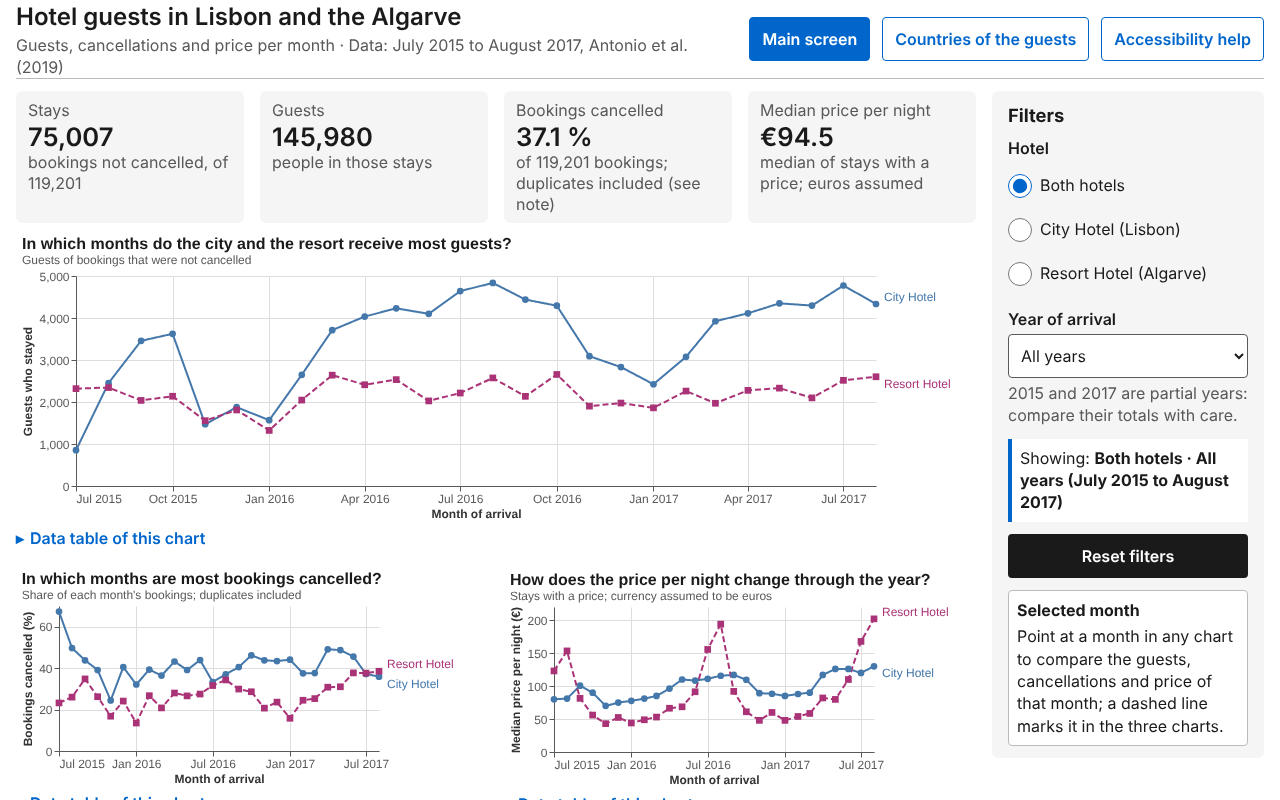

detail.html


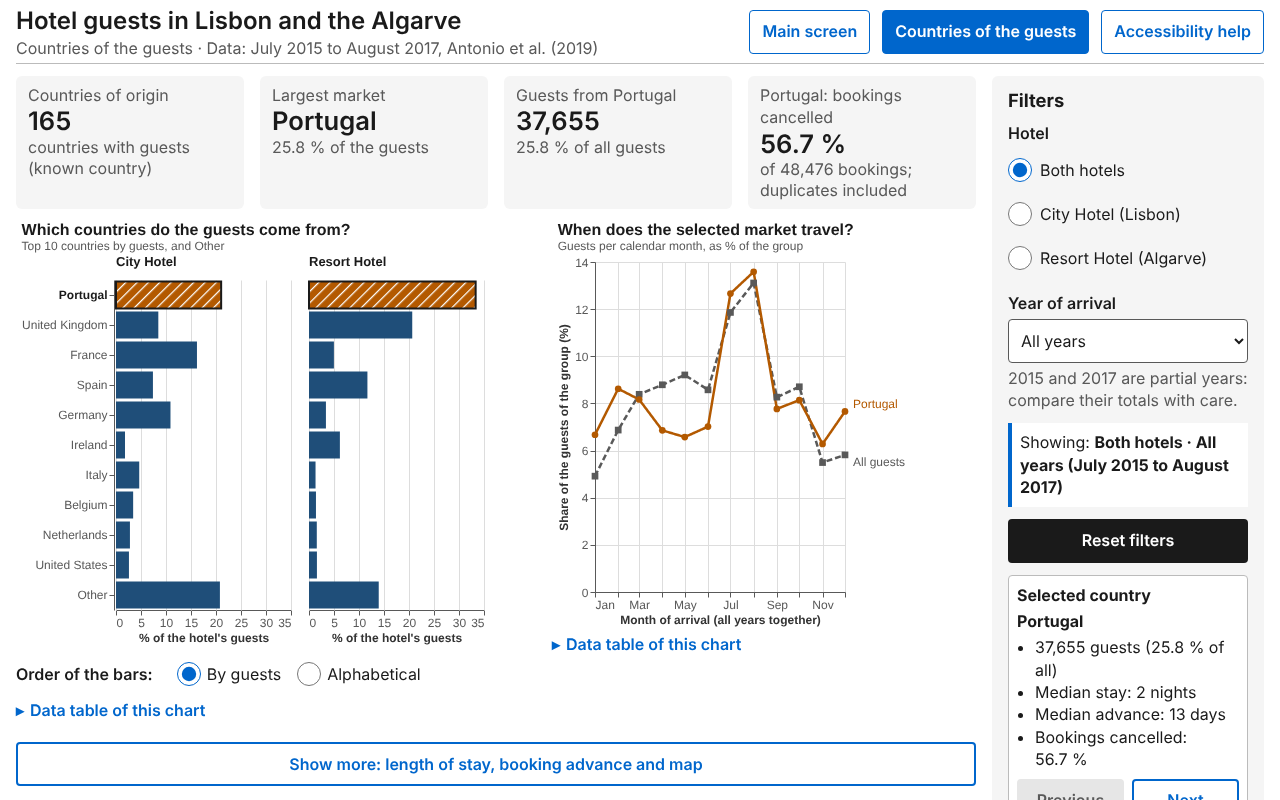

In [21]:
# ── Screenshots at the minimum screen size (1280 x 800 px) ───────────────────
from IPython.display import Image, display
for name in PAGES:
    print(name)
    display(Image(filename=OUTPUT_DIR / name.replace('.html', '_1280x800.png'), width=640))

## 6. Export

In [22]:
# ── Export the results ────────────────────────────────────────────────────────
summary.to_csv(OUTPUT_DIR / 'first_load_checks.csv', index=False)
interaction_checks.to_csv(OUTPUT_DIR / 'interaction_checks.csv', index=False)
keyboard_checks.to_csv(OUTPUT_DIR / 'keyboard_checks.csv', index=False)
operability.to_csv(OUTPUT_DIR / 'wcag_operability_review.csv', index=False)
alternative_checks.to_csv(OUTPUT_DIR / 'text_alternative_checks.csv', index=False)
text_audit.to_csv(OUTPUT_DIR / 'contrast_and_text_size.csv', index=False)
layout_checks.to_csv(OUTPUT_DIR / 'zoom_and_tablet_checks.csv', index=False)
structure_checks.to_csv(OUTPUT_DIR / 'page_structure_checks.csv', index=False)
review.to_csv(OUTPUT_DIR / 'wcag_other_items_review.csv', index=False)
pd.DataFrame([(r['page'], label, value, context) for r in first_load for label, value, context in r['kpis']],
             columns=['page', 'KPI', 'value', 'context']).to_csv(OUTPUT_DIR / 'first_load_kpis.csv', index=False)
sorted(path.name for path in OUTPUT_DIR.iterdir())

['contrast_and_text_size.csv',
 'detail_1280x800.png',
 'detail_200_640x400.png',
 'detail_full_page.png',
 'detail_keyboard_focus_1280x800.png',
 'detail_show_more_full_page.png',
 'detail_tablet_1024x768.png',
 'detail_tablet_768x1024.png',
 'first_load_checks.csv',
 'first_load_kpis.csv',
 'index_1280x800.png',
 'index_200_640x400.png',
 'index_full_page.png',
 'index_keyboard_focus_1280x800.png',
 'index_month_linked_1280x800.png',
 'index_tablet_1024x768.png',
 'index_tablet_768x1024.png',
 'interaction_checks.csv',
 'keyboard_checks.csv',
 'page_structure_checks.csv',
 'text_alternative_checks.csv',
 'wcag_operability_review.csv',
 'wcag_other_items_review.csv',
 'zoom_and_tablet_checks.csv']

## Conclusions

### Task 6.4 (pages)
1. `index.html` and `detail.html` open by double-click, with no server and no internet: the data, the chart specs and the Vega libraries are all local files loaded with `<script src>`.
2. Both show data at first load: four KPIs and every chart, as SVG, with no error in the console.
3. Each page has `lang="en"`, skip links to the charts and the filters, and a heading for each chart.

### Task 6.5 (interactions)
1. The nine interactions of Part 5 work in the browser; each check reads the result back from the page and compares it with the tables of task 6.1.
2. Every change is announced: the "Showing" line and the "Selected month" and "Selected country" boxes are live regions, the reset and the sort order are announced by a hidden message, and "Show more" uses `aria-expanded`.

### Task 6.6 (keyboard and focus)
1. Both screens can be used with the keyboard only; every data mark is reachable with the arrow keys and `Alt` + up/down arrow between series, with an SVG focus ring, a live announcement and a visible value box.
2. The Operability items of the WCAG checklist are reviewed in section 4.4: all met except the size of the data points (partly met, with other ways to do the same) and the phone item (not applicable).

### Task 6.7 (text alternatives and help)
1. Every chart has a short and a long text alternative and a data table, equal to pandas; the selected country has a fill pattern; `accessibility.html` explains the keys, the filters and how to report a problem.
2. The Perception, Comprehensibility, Robustness and help-page items are reviewed in section 4.7: all met, some in an adapted way (the page text was raised to 16 px in task 6.8, as the students decided).

### Limitations
- Checked in Chromium only (headless) and with the keyboard simulated by Playwright; no real screen reader was used, so the students should try the pages with NVDA or VoiceOver.
- 200 % zoom is simulated with a 640 x 400 viewport at device scale 2, which is how browsers lay out a zoomed page.

### Next steps
- Task 6.8: screenshots of both screens and the final review with the students.